# Verificación del entorno de deep learning

LRT4012 Visión en Robótica · Otoño 2026

Las pruebas utilizan datos sintéticos y no descargan modelos ni conjuntos de datos.

In [8]:
import importlib.metadata as metadata
import platform
import time

import cv2
import matplotlib.pyplot as plt
import numpy as np
import onnx
import onnxruntime as ort
import pandas as pd
import torch
import torchvision
import transformers
from IPython.display import display

packages = [
    "torch", "torchvision", "opencv-python", "numpy",
    "pandas", "transformers", "onnx", "onnxruntime",
]
versions = pd.DataFrame({
    "paquete": packages,
    "version": [metadata.version(name) for name in packages],
})
cuda_ready = torch.cuda.is_available()
device = torch.device("cuda" if cuda_ready else "cpu")

print(f"Python: {platform.python_version()}")
print(f"Dispositivo seleccionado: {device}")
if cuda_ready:
    print(f"GPU: {torch.cuda.get_device_name(0)}")
display(versions)

checks = [{"prueba": "Importacion de paquetes", "estado": "APROBADA"}]

Python: 3.11.9
Dispositivo seleccionado: cuda
GPU: NVIDIA T1000 8GB


,paquete,version
0,torch,2.14.1+cu126
1,torchvision,0.29.1+cu126
2,opencv-python,4.14.0.94
3,numpy,2.4.6
4,pandas,3.1.1
5,transformers,5.22.1
6,onnx,1.23.2
7,onnxruntime,1.31.1


## Operación con tensores

La multiplicación se ejecuta en CUDA cuando existe una GPU compatible; en los demás equipos se ejecuta en CPU.

In [9]:
torch.manual_seed(4012)
matrix = torch.rand((1024, 1024), device=device)
if cuda_ready:
    torch.cuda.synchronize()
start = time.perf_counter()
product = matrix @ matrix.T
if cuda_ready:
    torch.cuda.synchronize()
elapsed_ms = 1000 * (time.perf_counter() - start)

assert product.shape == (1024, 1024)
assert torch.isfinite(product).all()
print(f"Multiplicación de matrices: {elapsed_ms:.2f} ms en {device}")
checks.append({"prueba": "Operación con tensores", "estado": "APROBADA"})

Multiplicación de matrices: 9.31 ms en cuda


## Red convolucional

MobileNetV3-Small procesa una imagen sintética sin utilizar pesos preentrenados.

In [10]:
from torchvision.models import mobilenet_v3_small

cnn = mobilenet_v3_small(weights=None).to(device).eval()
cnn_input = torch.rand((1, 3, 224, 224), device=device)
with torch.inference_mode():
    cnn_output = cnn(cnn_input)

assert cnn_output.shape == (1, 1000)
print("Forma de salida de MobileNetV3-Small:", tuple(cnn_output.shape))
checks.append({"prueba": "Red convolucional", "estado": "APROBADA"})
del cnn, cnn_input, cnn_output

Forma de salida de MobileNetV3-Small: (1, 1000)


## Vision transformer

Un transformer compacto procesa una imagen sintética sin descargar un modelo externo.

In [11]:
from transformers import ViTConfig, ViTForImageClassification

vit_config = ViTConfig(
    image_size=32, patch_size=8, num_channels=3, hidden_size=64,
    num_hidden_layers=2, num_attention_heads=4,
    intermediate_size=128, num_labels=3,
)
vit = ViTForImageClassification(vit_config).to(device).eval()
vit_input = torch.rand((1, 3, 32, 32), device=device)
with torch.inference_mode():
    vit_output = vit(vit_input).logits

assert vit_output.shape == (1, 3)
print("Forma de salida del vision transformer:", tuple(vit_output.shape))
checks.append({"prueba": "Vision transformer", "estado": "APROBADA"})
del vit, vit_input, vit_output

Forma de salida del vision transformer: (1, 3)


## Vision con OpenCV

La imagen sintética permite comprobar conversión de color, detección de bordes y visualización.

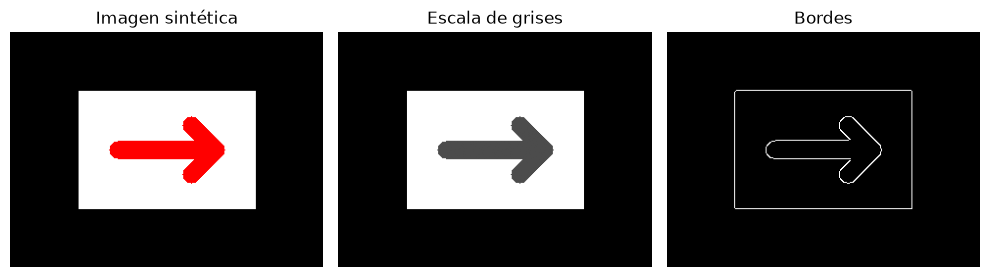

In [12]:
image_bgr = np.zeros((240, 320, 3), dtype=np.uint8)
cv2.rectangle(image_bgr, (70, 60), (250, 180), (255, 255, 255), -1)
cv2.arrowedLine(image_bgr, (110, 120), (210, 120), (0, 0, 255), 18, tipLength=0.35)
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)
edges = cv2.Canny(gray, 80, 160)

fig, axes = plt.subplots(1, 3, figsize=(10, 3))
axes[0].imshow(image_rgb)
axes[0].set_title("Imagen sintética")
axes[1].imshow(gray, cmap="gray")
axes[1].set_title("Escala de grises")
axes[2].imshow(edges, cmap="gray")
axes[2].set_title("Bordes")
for axis in axes:
    axis.axis("off")
plt.tight_layout()
plt.show()

assert np.count_nonzero(edges) > 0
checks.append({"prueba": "OpenCV y visualización", "estado": "APROBADA"})

## ONNX Runtime

El modelo mínimo calcula $y=x+1$ con el proveedor de ejecución de CPU.

In [13]:
from onnx import TensorProto, helper

input_info = helper.make_tensor_value_info("x", TensorProto.FLOAT, [None, 2])
output_info = helper.make_tensor_value_info("y", TensorProto.FLOAT, [None, 2])
one = helper.make_tensor("one", TensorProto.FLOAT, [1], [1.0])
node = helper.make_node("Add", ["x", "one"], ["y"])
graph = helper.make_graph([node], "hello_onnx", [input_info], [output_info], [one])
model = helper.make_model(graph, opset_imports=[helper.make_opsetid("", 17)])
model.ir_version = 10
onnx.checker.check_model(model)

session = ort.InferenceSession(model.SerializeToString(), providers=["CPUExecutionProvider"])
onnx_input = np.array([[2.0, 5.0]], dtype=np.float32)
onnx_output = session.run(None, {"x": onnx_input})[0]
np.testing.assert_allclose(onnx_output, np.array([[3.0, 6.0]], dtype=np.float32))
print("Salida ONNX:", onnx_output)
checks.append({"prueba": "ONNX Runtime", "estado": "APROBADA"})

Salida ONNX: [[3. 6.]]


## Resultado

In [14]:
summary = pd.DataFrame(checks)
display(summary)
assert summary["estado"].eq("APROBADA").all()
print(f"Entorno listo: {len(summary)} de {len(summary)} pruebas aprobadas.")

,prueba,estado
0,Importacion de paquetes,APROBADA
1,Operación con tensores,APROBADA
2,Red convolucional,APROBADA
3,Vision transformer,APROBADA
4,OpenCV y visualización,APROBADA
5,ONNX Runtime,APROBADA


Entorno listo: 6 de 6 pruebas aprobadas.
